# Análisis exploratorio (EDA)

Analizamos solo el conjunto de entrenamiento (train.csv).

In [70]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import graficos as g

# clave: (nombre, ruta, separador, descripción)
OPCIONES = {
    "1": ("train.csv",    "../data/silver/train.csv",    ",",
          "Datos limpios, solo entrenamiento (80 %). El que usamos para el EDA y las conclusiones."),
    "2": ("test.csv",     "../data/silver/test.csv",     ",",
          "Datos limpios, solo test (20 %). Solo para comparar con train, no para decidir nada."),
    "3": ("Property.csv", "../data/bronze/Property.csv", ";",
          "Datos originales sin limpiar (191.393 anuncios, venta y alquiler, precios en rupias)."),
    "4": ("salida.csv",   "../data/silver/salida.csv",   ",",
          "Datos limpios completos (solo ventas), antes de separar train y test."),
}

print("¿Qué dataset quieres usar?\n")
for k, (n, _, _, desc) in OPCIONES.items():
    print(f"  {k}) {n:<13} {desc}")
eleccion = input("\nNúmero (Enter = 1, train): ").strip() or "1"

if eleccion not in OPCIONES:
    raise ValueError(f"Opción '{eleccion}' no válida. Elige 1, 2, 3 o 4.")

nombre, ruta, sep, _ = OPCIONES[eleccion]
train = pd.read_csv(ruta, sep=sep)   # se llama "train" para no tocar el resto de celdas
print(f"\nUsando {nombre}: {train.shape}")

# La fecha viene distinta en el archivo original que en los procesados
if nombre == "Property.csv":
    formato_fecha = "%m-%d-%Y"
else:
    formato_fecha = "%Y-%m-%d"
    train["date_added"] = pd.to_datetime(train["date_added"])

# Solo usamos las columnas que existen en el dataset elegido
cols_num = [c for c in ["price", "Total_Area", "baths", "bedrooms", "dist_centro_km"]
            if c in train.columns]

¿Qué dataset quieres usar?

  1) train.csv     Datos limpios, solo entrenamiento (80 %). El que usamos para el EDA y las conclusiones.
  2) test.csv      Datos limpios, solo test (20 %). Solo para comparar con train, no para decidir nada.
  3) Property.csv  Datos originales sin limpiar (191.393 anuncios, venta y alquiler, precios en rupias).
  4) salida.csv    Datos limpios completos (solo ventas), antes de separar train y test.

Usando salida.csv: (83656, 12)


## 1. Tipos de variables

In [71]:
tipos = pd.DataFrame({
    "tipo": train.dtypes.astype(str),
    "valores_distintos": train.nunique(),
})
tipos

,tipo,valores_distintos
location_id,int64,4033
property_type,str,2
price,float64,1632
location,str,1446
city,str,5
latitude,float64,6975
longitude,float64,7431
baths,float64,12
bedrooms,float64,12
date_added,datetime64[us],134


## Conclusiones:

- Variables numéricas: "price", "Total_Area", "baths", "bedrooms", "dist_centro_km", "latitude" y "longitude".
- Variables Categóricas: "property_type", "city", "location"  y "location_id".

- "location_id" se lee como número, pero es un código, asi que la pasamos a texto para que no se trate como numérica.

In [72]:
train["location_id"] = train["location_id"].astype(str)
train.describe().round(1).T

,count,mean,min,25%,50%,75%,max,std
price,83656.0,142856.4,1057.8,40086.8,77946.7,150882.5,8073047.2,229601.3
latitude,83656.0,29.6,24.7,24.9,31.4,33.5,34.0,3.7
longitude,83656.0,71.3,66.8,67.1,73.1,74.3,74.5,3.2
baths,64964.0,4.1,1.0,3.0,4.0,5.0,12.0,1.8
bedrooms,74980.0,3.9,1.0,3.0,4.0,5.0,12.0,1.7
date_added,83656,2019-05-15 14:47:08.497657,2018-08-05 00:00:00,2019-05-03 00:00:00,2019-06-26 00:00:00,2019-07-09 00:00:00,2019-08-06 00:00:00,NaN
dist_centro_km,83656.0,13.7,0.0,8.5,12.8,17.1,87.9,7.4
Total_Area,83656.0,245.5,10.1,118.9,161.9,252.9,4856.2,251.0


## 2. Valores ausentes


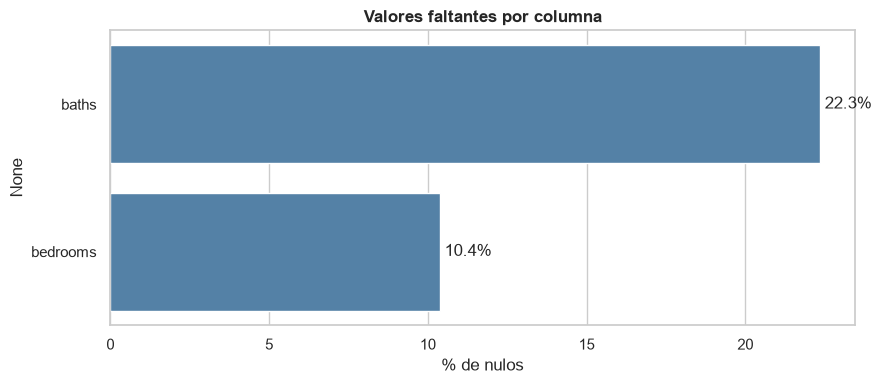

In [73]:
g.plot_valores_nulos(train);

In [74]:
print("% de ausentes por ciudad")
train.groupby("city")[["baths", "bedrooms"]].apply(lambda d: d.isna().mean()).round(3)

% de ausentes por ciudad


,baths,bedrooms
city,,
Faisalabad,0.451,0.365
Islamabad,0.205,0.116
Karachi,0.222,0.101
Lahore,0.201,0.060
Rawalpindi,0.247,0.141


## Conclusiones:

- Hay un 22,4 % de ausentes en "baths" y un 10,4 % en "bedrooms".

## Decisión: 

- Imputarlos ajustando solo con el train, con la mediana por tipo de vivienda y superficie y añadir una variable indicadora de dato ausente ("baths_ausente", "bedrooms_ausente"), porque el hecho de que falte puede aportar información.

## 3. Variable objetivo (price)

### 3.1 Distribución de price

Miramos la forma del precio y si tiene cola larga.



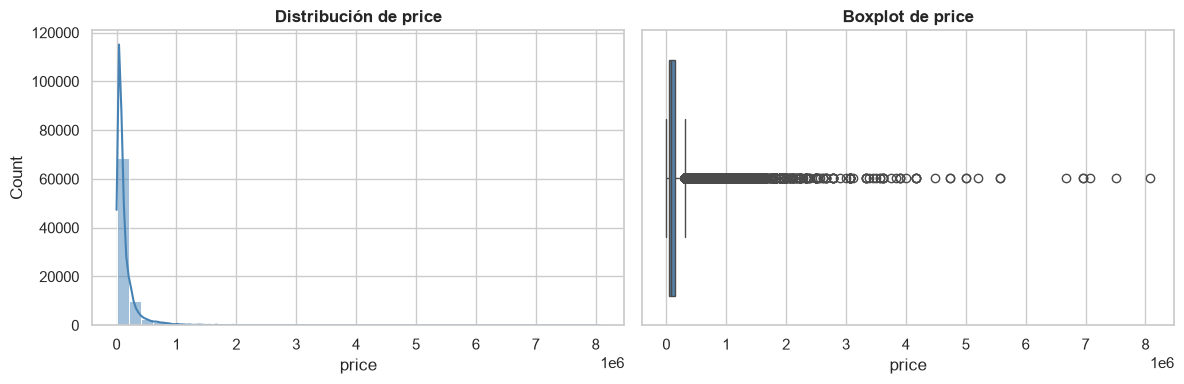

In [75]:
g.plot_distribucion_numerica(train, "price");

### 3.2 Distribución de log(price)

Repetimos el gráfico en escala logarítmica para ver si la forma mejora.


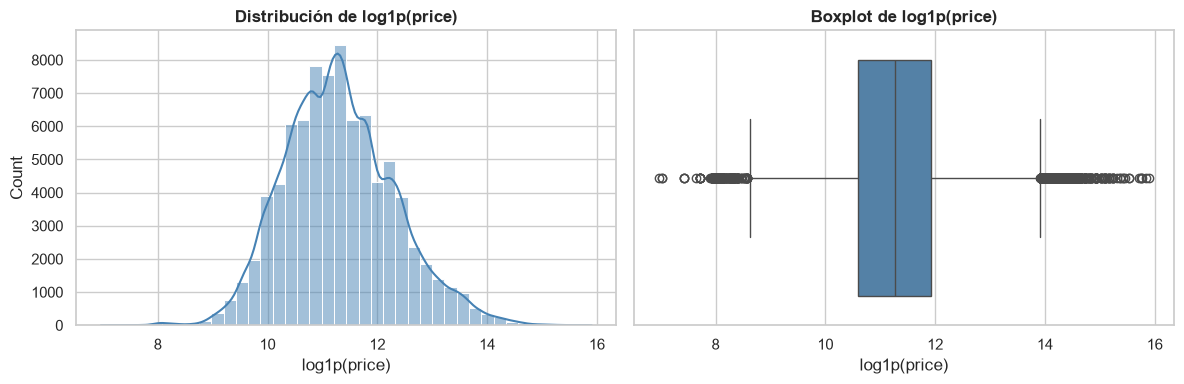

In [76]:
g.plot_distribucion_numerica(train, "price", log=True);

### 3.3 Asimetría antes y después del logaritmo

Cuantificamos la mejora comparando la asimetría de price y de log(price).

**Decisión del apartado:** modelar log(price) y deshacer la transformación al calcular el error final.

In [77]:
print("Asimetría de price:", round(train["price"].skew(), 2))
print("Asimetría de log(price):", round(np.log(train["price"]).skew(), 2))

Asimetría de price: 7.75
Asimetría de log(price): 0.33


## 4. Variables numéricas

### 4.1 Distribución de las variables numéricas

Miramos la forma de la superficie, los baños, las habitaciones y la distancia al centro.

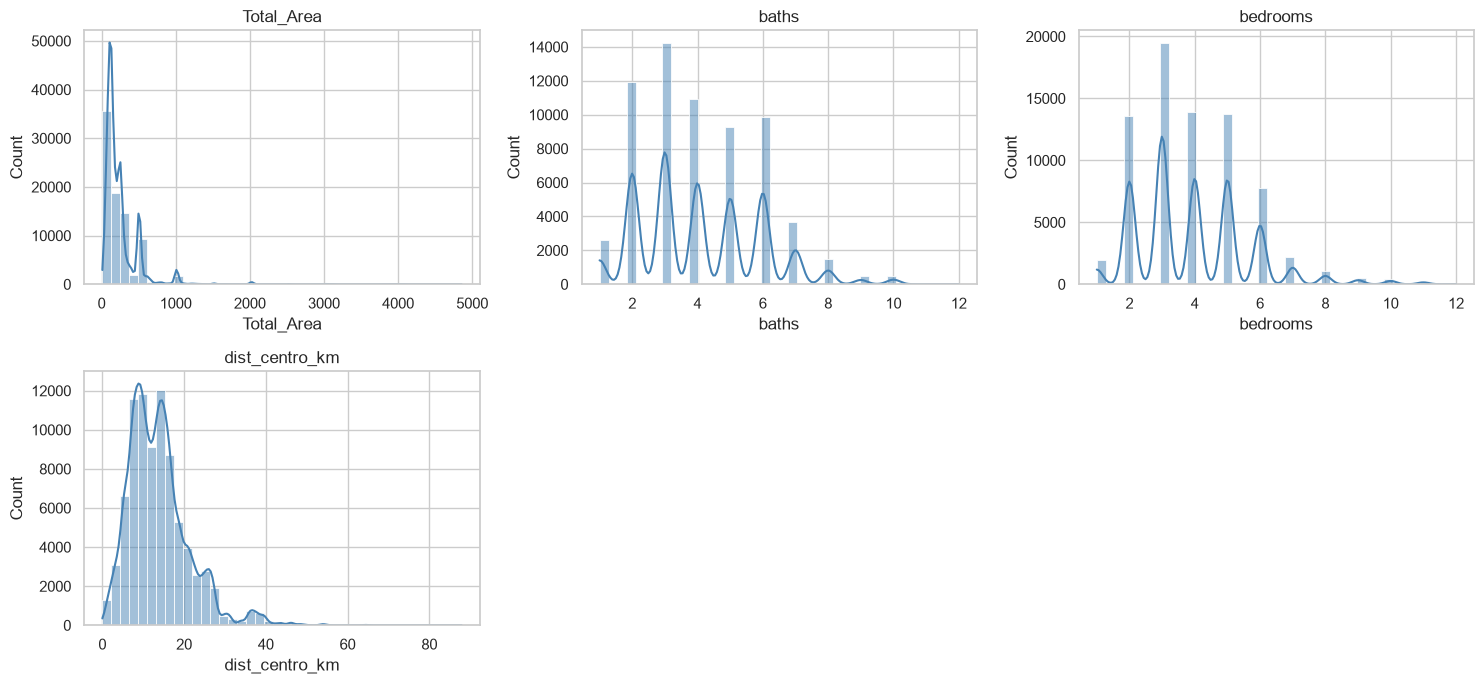

In [78]:
g.plot_distribuciones_numericas(train, cols=[c for c in cols_num if c != "price"]);

### 4.2 Atípicos (regla del IQR)

Medimos qué porcentaje de cada variable queda fuera de 1,5 veces el rango intercuartílico.


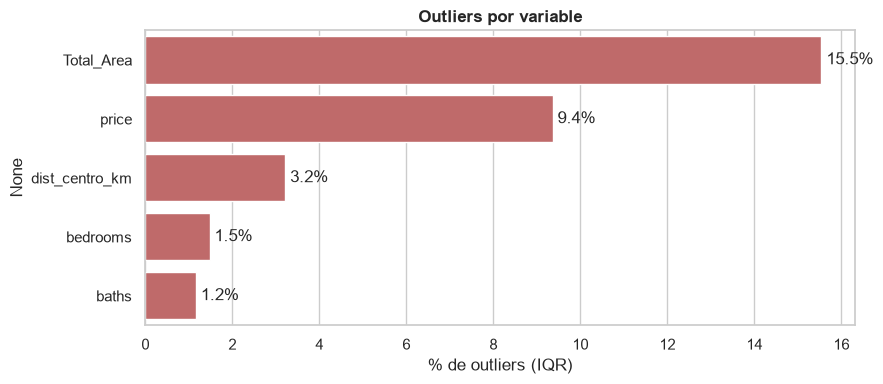

In [79]:
g.plot_outliers_iqr(train, cols=cols_num);

## 5. Variables categóricas

### 5.1 Anuncios por ciudad

Miramos si las ciudades están equilibradas.


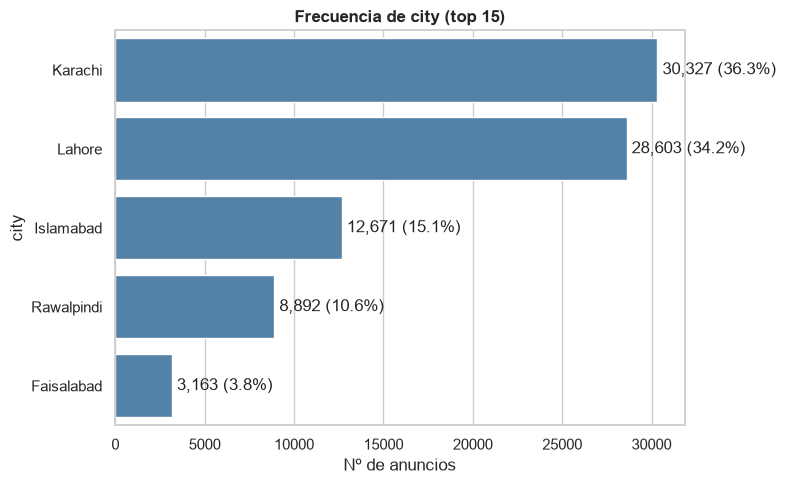

In [80]:
g.plot_categorica(train, "city");

### 5.2 Anuncios por tipo de vivienda

Miramos qué tipos dominan y cuáles tienen pocos anuncios.


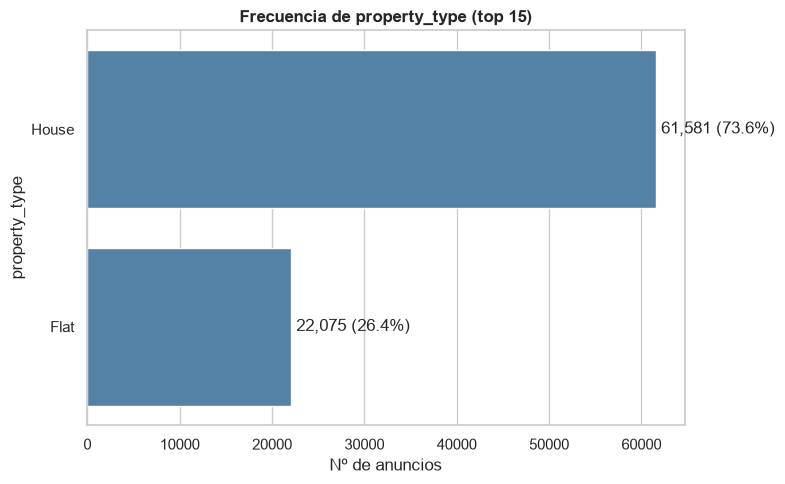

In [81]:
g.plot_categorica(train, "property_type");

### 5.3 Zonas con más anuncios

Miramos las 20 zonas más frecuentes de "location".



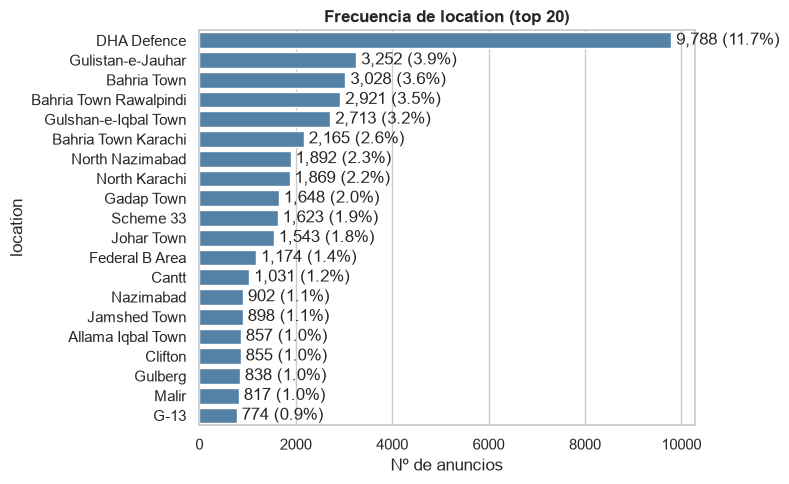

In [82]:
g.plot_categorica(train, "location", top_n=20);

### 5.4 Cuántas zonas tienen pocos anuncios

Resumimos cuántos anuncios tiene cada zona (mediana, mínimo, máximo).


In [83]:
train["location"].value_counts().describe()

count    1446.000000
mean       57.853389
std       335.006061
min         1.000000
25%         3.000000
50%         7.000000
75%        22.000000
max      9788.000000
Name: count, dtype: float64

## 6. Relación con el precio

### 6.1 Correlaciones (Spearman)

Miramos qué variables numéricas se relacionan más con el precio y entre sí.


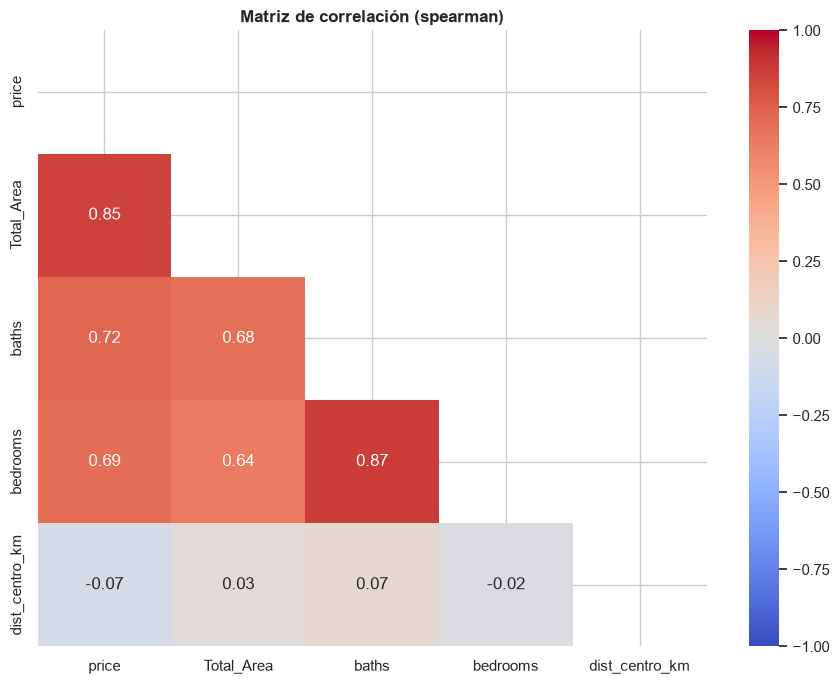

In [84]:
g.plot_correlaciones(train, cols=cols_num);

### 6.2 Precio frente a superficie

Miramos cómo crece el precio con la superficie, por tipo de vivienda (ambos ejes en escala logarítmica).


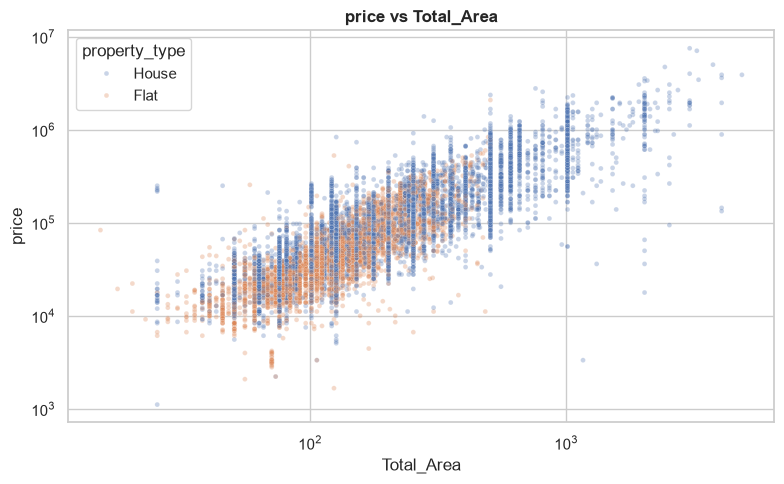

In [85]:
if "Total_Area" in train.columns:
    g.plot_scatter(train, "Total_Area", "price", hue="property_type", logx=True, logy=True);
else:
    print("Este dataset no tiene Total_Area: celda omitida.")

### 6.3 Precio por ciudad

Comparamos el precio entre las ciudades (escala logarítmica).


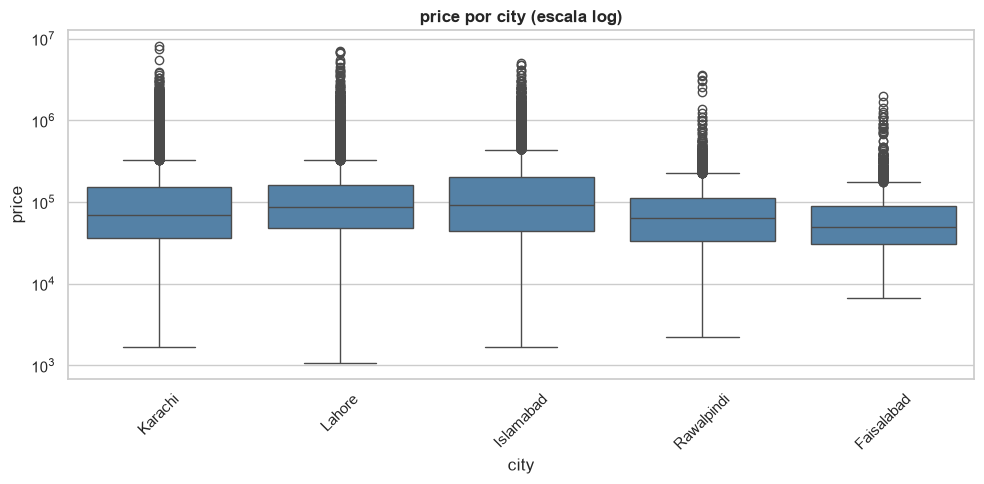

In [86]:
g.plot_boxplot_por_categoria(train, "city", "price");

### 6.4 Precio por tipo de vivienda

Comparamos el precio entre los tipos de vivienda (escala logarítmica).


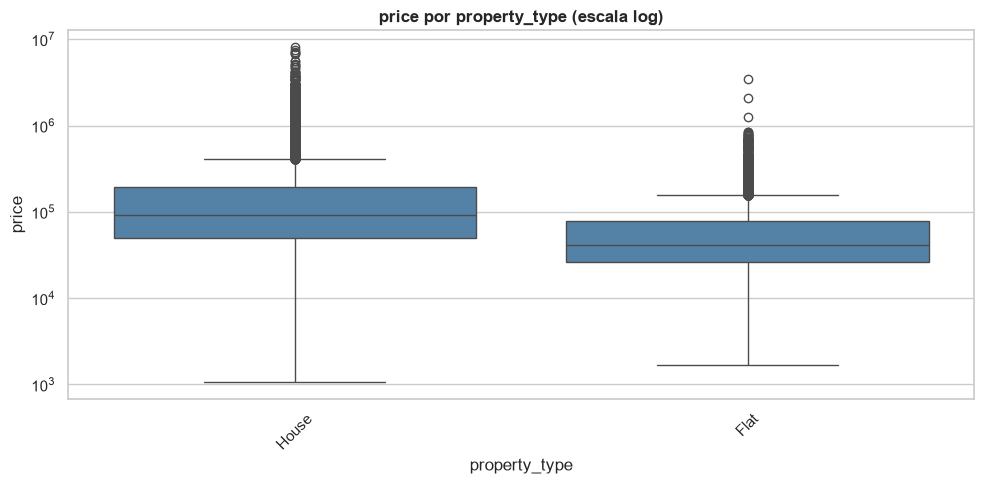

In [87]:
g.plot_boxplot_por_categoria(train, "property_type", "price");

## 7. Ubicación

### 7.1 Mapa de coordenadas

Miramos dónde están los anuncios y si hay coordenadas fuera de su ciudad.


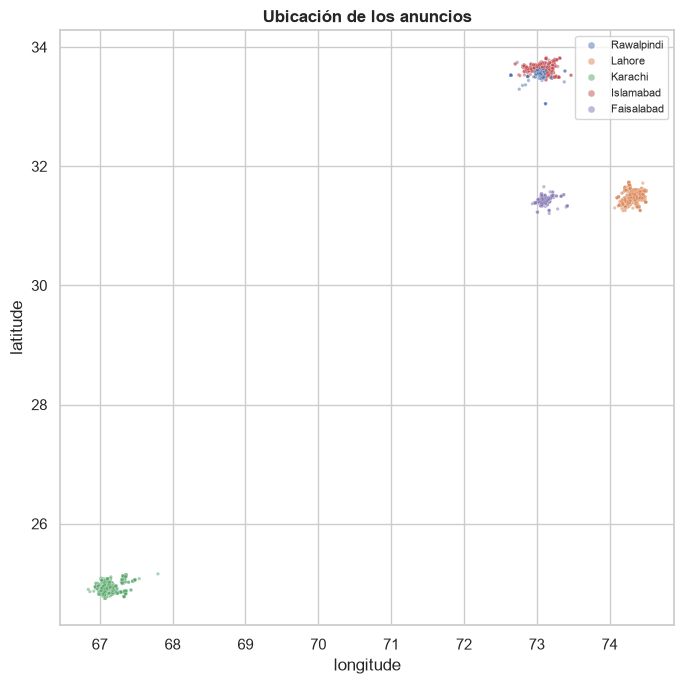

In [88]:
g.plot_mapa_coordenadas(train);

### 7.2 Precio mediano según la distancia al centro

Agrupamos los anuncios por tramos de distancia al centro y comparamos el precio mediano.


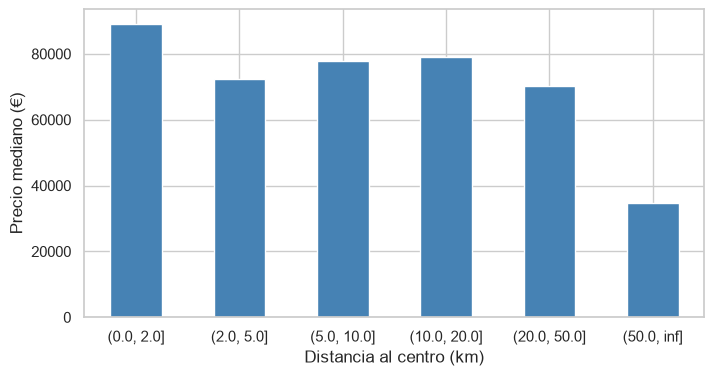

dist_centro_km
(0.0, 2.0]      89082.0
(2.0, 5.0]      72379.0
(5.0, 10.0]     77947.0
(10.0, 20.0]    79060.0
(20.0, 50.0]    70152.0
(50.0, inf]     34759.0
Name: price, dtype: float64

In [89]:
if "dist_centro_km" in train.columns:
    tramos = pd.cut(train["dist_centro_km"], bins=[0, 2, 5, 10, 20, 50, np.inf])
    mediana = train.groupby(tramos, observed=True)["price"].median()
    mediana.plot(kind="bar", color=g.COLOR, figsize=(8, 4))
    plt.ylabel("Precio mediano (€)")
    plt.xlabel("Distancia al centro (km)")
    plt.xticks(rotation=0)
    plt.show()
    display(mediana.round(0))
else:
    print("Este dataset no tiene dist_centro_km: celda omitida.")

## 8. Fecha

### 8.1 Anuncios por mes

"date_added" es la fecha de la última actualización, no la de publicación. Miramos cómo se reparten los anuncios en el tiempo.


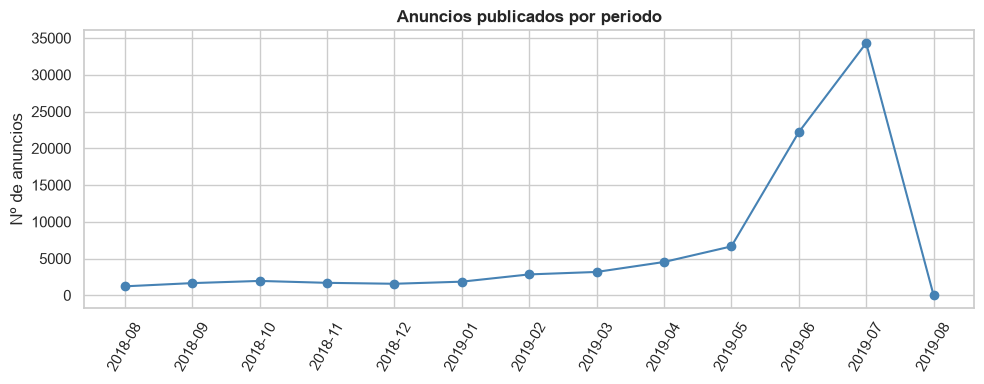

In [90]:
g.plot_serie_temporal(train, formato=formato_fecha);